In [51]:
#Write out all steps you would take to accomplish this project from start to finish
#File name CFCB_Consumer_Complaints_2024
#Import the file as dataframe
#Split the dataset into 2 tables - one with actual complaints(A) and the other with blank complaint boxes(B)
#Run regex text cleaning on table A
# -make all letters lowercase
# -remove all punctuation and extra characters
# -if there are any links or attached files, remove those
# -remove redaction placeholders (occurences of multiple Xs at once)

In [52]:
#Make sets of charts - bar/line/pie/scatter (whichever is appropriate) - for both A and B
#Doing it for both allows for comparison between A and B
#Tables can be done for the following:
# -complaints by product type
# -complaints by issue/subissue
# -complaint by state
# -complaint by timely response
#Table B is only to be used here, all analysis past this point is only for Table A

In [53]:
#Perform word frequency analysis and TF-IDF analysis
#Since there is at least 150+ complaints in Table A, amount of topics needed for Topic modeling must be relatively high so as to prevent over-generalized topics
#Use the various statistical diagnostics to see what is an ideal number of topics:
# -perplexity
# -coherence
# -diversity
# -stability

In [54]:
#This dataset has various columns that can be of use for the final project
#Product
#Issue/subissue
#State
#Company response

In [55]:
#After running TF-IDF and LDA, find the dominant topic per complaint
#Build a second table where the topics are rows and the company response are columns
#Compare topic labels to company responses
#Not looking for causation, just correlation

In [56]:
#You can make a second table just like the above but with customer dispute (True/False)
#Which topics get the most disputes and which ones get resolved easily

In [57]:
#Bonus:
#Try to label topics with proper descriptions

In [58]:
import pandas as pd
import io
import glob
import matplotlib.pyplot as plt
import numpy as np

In [59]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [60]:
#Put the files in google drive so it is easier to open
files = glob.glob('/content/drive/MyDrive/Colab Notebooks/Consumer Complaint Data/CFPB_Consumer_Complaints_2024.csv')
print(files)  # Verify it finds your files

['/content/drive/MyDrive/Colab Notebooks/Consumer Complaint Data/CFPB_Consumer_Complaints_2024.csv']


In [61]:
#checking size of df
df = pd.concat([pd.read_csv(f) for f in files])
print(df.shape)

(500, 18)


In [62]:
#make sure all data types are valid
df.dtypes

,0
date_received,object
product,object
subproduct,object
issue,object
subissue,object
consumer_complaint_narrative,object
company_public_response,object
company_name,object
state,object
zip_code,float64


In [63]:
complaints_df = df.copy()
complaints_df.head()

,date_received,product,subproduct,issue,subissue,consumer_complaint_narrative,company_public_response,company_name,state,zip_code,tags,consumer_consent_provided,submitted_via,date_sent_to_company,company_response_to_consumer,timely_response,consumer_disputed,complaint_id
0,10/16/2020,"Credit reporting, credit repair services, or o...",Credit repair services,Fraud or scam,NaN,NaN,NaN,ERC,NaN,NaN,NaN,NaN,Phone,10/19/2020,Closed with explanation,True,NaN,3903929
1,10/24/2014,Credit reporting,NaN,Incorrect information on credit report,Account terms,NaN,NaN,ERC,LA,70816.0,"Older American, Servicemember",NaN,Web,10/29/2014,Closed with non-monetary relief,True,False,1085252
2,3/14/2015,Credit reporting,NaN,Incorrect information on credit report,Account terms,NaN,NaN,ERC,AL,35242.0,NaN,NaN,Web,3/20/2015,Closed with non-monetary relief,True,False,1283279
3,7/13/2015,Debt collection,"Other (i.e. phone, health club, etc.)",Cont'd attempts collect debt not owed,Debt was paid,"During my time as an employee for XXXX, I was ...",Company believes it acted appropriately as aut...,ERC,CO,80916.0,NaN,Consent provided,Web,7/13/2015,Closed with non-monetary relief,True,False,1465916
4,9/21/2018,Debt collection,Other debt,Attempts to collect debt not owed,Debt was paid,NaN,Company believes it acted appropriately as aut...,ERC,KY,41008.0,NaN,Consent not provided,Web,9/21/2018,Closed with explanation,True,NaN,3025580


In [64]:
complaints_df.dropna(subset=['consumer_complaint_narrative'], inplace=True)
complaints_df.reset_index(drop=True, inplace=True)
print(complaints_df.shape)


(200, 18)


In [65]:
#complaints_df["narrative_cleaned"] = complaints_df["consumer_complaint_narrative"]

#Build a simple cleaning function
import re

def clean_text(text):
    # Handle missing values.
    if pd.isna(text):
        return ""

    # Make sure the input is a string.
    text = str(text)

    # Make uppercase and lowercase consistent.
    text = text.lower()

    # Remove website links.
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    # Keep letters, numbers, and spaces; replace punctuation with spaces.
    text = re.sub(r"[^a-z0-9\s]", " ", text)

    # Remove all instances of multiple x
    text = re.sub(r"(x{2,})", "*", text)

    # Replace repeated spaces with one space.
    text = re.sub(r"\s+", " ", text).strip()

    # Cleans punctuation but preserves internal apostrophes
    cleaned_text = re.sub(r"(?<!\w)'|'(?!\w)|[^a-zA-Z']", " ", text)
    # Remove spaces at the beginning and end.
    #text = text.strip()

    return text

#Will remove, extra whitespace, capitalization, punctionation, and website links
test = "  I did NOT receive my refund!!! Visit https://example.com  "
print(clean_text(test))

i did not receive my refund visit


In [66]:
complaints_df['narrative_cleaned']=complaints_df['consumer_complaint_narrative'].apply(clean_text)
complaints_df[['consumer_complaint_narrative' , 'narrative_cleaned']].head()

,consumer_complaint_narrative,narrative_cleaned
0,"During my time as an employee for XXXX, I was ...",during my time as an employee for * i was enco...
1,I have been monitoring my credit weekly for 2 ...,i have been monitoring my credit weekly for 2 ...
2,I previously had phone service with XXXX XXXX....,i previously had phone service with * * my bil...
3,Several debt collectors have called me on beha...,several debt collectors have called me on beha...
4,On XX/XX/2020 I settled and paid a debt with E...,on * * 2020 i settled and paid a debt with enh...


In [67]:
complaints_df.to_csv('cleaned_complaints.csv', index=False)

In [68]:
#Change up the above downloaded file
#Reupload the updated file
#Continue the code with new file

In [69]:
cleaned_files = glob.glob('/content/drive/MyDrive/Colab Notebooks/Consumer Complaint Data/cleaned_complaints.csv')
print(cleaned_files)
#checking size of df
cleaned_df = pd.concat([pd.read_csv(f) for f in cleaned_files])
print(cleaned_df.shape)

['/content/drive/MyDrive/Colab Notebooks/Consumer Complaint Data/cleaned_complaints.csv']
(200, 19)


In [70]:
def remove_star(text):
  # Handle missing values.
    if pd.isna(text):
        return ""
    text = re.sub(r"\*", "", text)
    # Replace repeated spaces with one space.
    text = re.sub(r"\s+", " ", text).strip()
    return text

cleaned_df['narrative_cleaned']=cleaned_df['narrative_cleaned'].apply(remove_star)
cleaned_df[['consumer_complaint_narrative' , 'narrative_cleaned']].head()

,consumer_complaint_narrative,narrative_cleaned
0,"During my time as an employee for XXXX, I was ...",during my time as an employee for i was encour...
1,I have been monitoring my credit weekly for 2 ...,i have been monitoring my credit weekly for 2 ...
2,I previously had phone service with XXXX XXXX....,i previously had phone service with my bill wa...
3,Several debt collectors have called me on beha...,several debt collectors have called me on beha...
4,On XX/XX/2020 I settled and paid a debt with E...,on 2020 i settled and paid a debt with enhance...


In [71]:
#Common way to do analysis of text is to break it down into words
#After sentences are split, they are placed in a column that is a list of all the words
#that make up the sentence
cleaned_df["tokens"] = cleaned_df["narrative_cleaned"].str.split()
cleaned_df[["narrative_cleaned", "tokens"]].head()

#Remove common words such as THE and AND
#Keep all negation type words
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

#The set of all english stop words that ARE NOT the 4 words
stop_words = set(ENGLISH_STOP_WORDS) - {"no", "not", "never", "without"}

In [72]:
from matplotlib import use
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

#Add all sentences together into one very long string
all_text = " ".join(cleaned_df["narrative_cleaned"])
#Break down all sentences into words
all_words = all_text.split()
stop_words = set(ENGLISH_STOP_WORDS) - {"no", "not", "never", "without"}
#Keep only the words not mentioned in stop_words
useful_words = [word for word in all_words if word not in stop_words]
#Prints out the 20 most common words
Counter(useful_words).most_common(20)


[('account', 317),
 ('debt', 311),
 ('credit', 283),
 ('not', 249),
 ('company', 193),
 ('collection', 178),
 ('report', 169),
 ('recovery', 136),
 ('enhanced', 128),
 ('information', 99),
 ('reporting', 87),
 ('no', 86),
 ('paid', 80),
 ('erc', 79),
 ('phone', 71),
 ('never', 71),
 ('called', 67),
 ('told', 65),
 ('received', 65),
 ('service', 64)]

In [73]:
from sklearn.feature_extraction.text import TfidfVectorizer
#Drops common filler words and creates a scoring/ranking for single/double word phrases
tfidf = TfidfVectorizer(stop_words="english", ngram_range=(1, 2))
#fit = read through all the complaints
#transform = convert each complaint into a numerical score
#high scores are more specific towards one complaint, whereas low scores appear in multiple
tfidf_matrix = tfidf.fit_transform(cleaned_df["narrative_cleaned"])
term_names = tfidf.get_feature_names_out()

complaint_number = 10
scores = tfidf_matrix[complaint_number].toarray()[0]

result = pd.DataFrame({"term": term_names, "score": scores})
result = result[result["score"] > 0].sort_values("score", ascending=False)

print(cleaned_df.loc[complaint_number, "narrative_cleaned"])
result.head(10)

i had a balance from and received a settlement letter i paid the balance due to settle and now enhanced recovery has no documentation of the payment 1 year later and will not remove the balance from my credit report i have called several times and tried to dispute but no results i was told by the agency that the debt would be removed and that i will receive a proof of payment i have not received any thing at this point


,term,score
1307,balance,0.243767
6896,payment,0.164409
871,agency debt,0.157078
1347,balance settle,0.157078
1343,balance received,0.157078
3752,documentation payment,0.157078
5671,letter paid,0.157078
6934,payment year,0.157078
5558,later remove,0.157078
1325,balance credit,0.157078


In [74]:
df2 = cleaned_df.copy()
df2.head()

,date_received,product,subproduct,issue,subissue,consumer_complaint_narrative,company_public_response,company_name,state,zip_code,tags,consumer_consent_provided,submitted_via,date_sent_to_company,company_response_to_consumer,timely_response,consumer_disputed,complaint_id,narrative_cleaned,tokens
0,7/13/2015,Debt collection,"Other (i.e. phone, health club, etc.)",Cont'd attempts collect debt not owed,Debt was paid,"During my time as an employee for XXXX, I was ...",Company believes it acted appropriately as aut...,ERC,CO,80916.0,NaN,Consent provided,Web,7/13/2015,Closed with non-monetary relief,True,False,1465916,during my time as an employee for i was encour...,"[during, my, time, as, an, employee, for, i, w..."
1,4/30/2016,Debt collection,"Other (i.e. phone, health club, etc.)",Cont'd attempts collect debt not owed,Debt was paid,I have been monitoring my credit weekly for 2 ...,Company believes it acted appropriately as aut...,ERC,CA,92008.0,NaN,Consent provided,Web,5/5/2016,Closed with non-monetary relief,True,True,1903865,i have been monitoring my credit weekly for 2 ...,"[i, have, been, monitoring, my, credit, weekly..."
2,3/9/2019,Debt collection,Other debt,Attempts to collect debt not owed,Debt was paid,I previously had phone service with XXXX XXXX....,Company believes it acted appropriately as aut...,ERC,KY,41091.0,NaN,Consent provided,Web,3/14/2019,Closed with explanation,True,NaN,3174523,i previously had phone service with my bill wa...,"[i, previously, had, phone, service, with, my,..."
3,5/12/2021,Debt collection,Other debt,Attempts to collect debt not owed,Debt was paid,Several debt collectors have called me on beha...,NaN,ERC,GA,30506.0,NaN,Consent provided,Web,5/12/2021,Closed with explanation,True,NaN,4372086,several debt collectors have called me on beha...,"[several, debt, collectors, have, called, me, ..."
4,7/9/2020,Debt collection,Other debt,Attempts to collect debt not owed,Debt was paid,On XX/XX/2020 I settled and paid a debt with E...,NaN,ERC,CA,92139.0,NaN,Consent provided,Web,7/21/2020,Closed with explanation,True,NaN,3737269,on 2020 i settled and paid a debt with enhance...,"[on, 2020, i, settled, and, paid, a, debt, wit..."


In [75]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer(stop_words="english", ngram_range=(1, 2), min_df=1)
word_matrix = vectorizer.fit_transform(df2["narrative_cleaned"])
print(word_matrix)

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 18597 stored elements and shape (200, 10298)>
  Coords	Values
  (0, 9475)	2
  (0, 3898)	8
  (0, 3929)	1
  (0, 6516)	4
  (0, 3144)	1
  (0, 2483)	1
  (0, 5752)	3
  (0, 1586)	1
  (0, 2566)	1
  (0, 6342)	2
  (0, 9213)	1
  (0, 6530)	2
  (0, 413)	6
  (0, 6711)	1
  (0, 6114)	1
  (0, 407)	1
  (0, 2683)	2
  (0, 9798)	1
  (0, 7033)	2
  (0, 9154)	1
  (0, 5882)	2
  (0, 4370)	1
  (0, 3746)	1
  (0, 10015)	2
  (0, 9746)	2
  :	:
  (199, 9886)	1
  (199, 7211)	1
  (199, 9314)	1
  (199, 9318)	1
  (199, 7511)	1
  (199, 2565)	1
  (199, 2758)	1
  (199, 3243)	1
  (199, 5529)	1
  (199, 5473)	1
  (199, 9313)	1
  (199, 1144)	1
  (199, 6039)	1
  (199, 5472)	1
  (199, 4197)	1
  (199, 7583)	1
  (199, 5742)	1
  (199, 8553)	1
  (199, 6194)	1
  (199, 6709)	1
  (199, 7838)	1
  (199, 982)	1
  (199, 3175)	1
  (199, 6197)	1
  (199, 2323)	1


In [76]:
feature_names = vectorizer.get_feature_names_out()
print(feature_names)
#

['00' '00 200' '00 2015' ... 'zeroes opposed' 'zip' 'zip code']


In [77]:
# word_matrix and vectorizer were created in the previous Topic Modeling section.

n_documents, n_features = word_matrix.shape

max_topics = min(15, n_documents - 1, n_features)

if max_topics < 2:
    raise ValueError("The dataset is too small to compare multiple topic counts.")

k_values = list(range(2, max_topics + 1))

print("Number of documents:", n_documents)
print("Vocabulary size:", n_features)
print("K values we will test:", k_values)

Number of documents: 200
Vocabulary size: 10298
K values we will test: [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]


In [78]:
from sklearn.decomposition import LatentDirichletAllocation

lda = LatentDirichletAllocation(
    n_components=6,
    random_state=0
)
document_topics = lda.fit_transform(word_matrix)

In [79]:
from sklearn.decomposition import LatentDirichletAllocation
import pandas as pd

perplexity_results = []
lda_models = {}

for k in k_values:
    model = LatentDirichletAllocation(
        n_components=k,
        random_state=42,
        max_iter=30
    )

    model.fit(word_matrix)

    lda_models[k] = model

    perplexity_results.append({
        "n_topics": k,
        "perplexity": model.perplexity(word_matrix)
    })

perplexity_df = pd.DataFrame(perplexity_results)
perplexity_df

,n_topics,perplexity
0,2,5986.754379
1,3,6077.834725
2,4,6209.415110
3,5,6363.130376
4,6,6412.615923
5,7,6486.767196
6,8,6479.850191
7,9,6649.549566
8,10,6677.831246
9,11,6547.376658


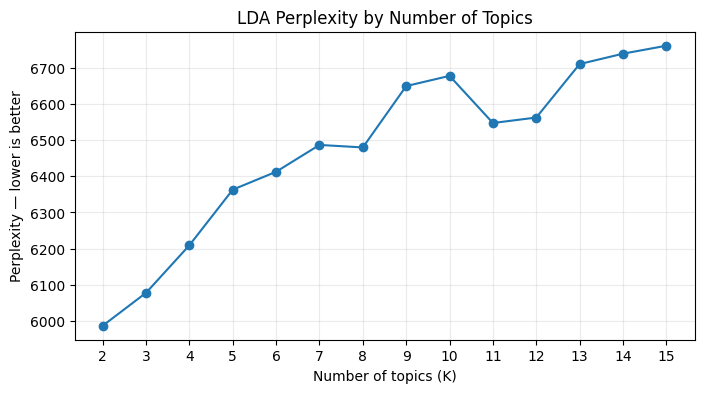

In [80]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.plot(
    perplexity_df["n_topics"],
    perplexity_df["perplexity"],
    marker="o"
)

plt.title("LDA Perplexity by Number of Topics")
plt.xlabel("Number of topics (K)")
plt.ylabel("Perplexity — lower is better")
plt.xticks(k_values)
plt.grid(alpha=0.25)
plt.show()

In [81]:
import numpy as np

def umass_coherence(model, document_term_matrix, top_n=8):
    # Calculate average UMass topic coherence.
    # Higher / closer to zero is generally better.

    # Convert counts to presence/absence.
    binary_matrix = document_term_matrix.copy()
    binary_matrix.data = np.ones_like(binary_matrix.data)

    document_frequency = np.asarray(binary_matrix.sum(axis=0)).ravel()

    topic_scores = []

    for topic_weights in model.components_:
        top_word_ids = topic_weights.argsort()[-top_n:][::-1]

        pair_scores = []

        for m in range(1, len(top_word_ids)):
            for l in range(m):
                word_m = top_word_ids[m]
                word_l = top_word_ids[l]

                # Number of documents containing both words.
                co_occurrence = (
                    binary_matrix[:, word_m]
                    .multiply(binary_matrix[:, word_l])
                    .sum()
                )

                # +1 smoothing prevents log(0).
                score = np.log(
                    (co_occurrence + 1)
                    / max(document_frequency[word_l], 1)
                )

                pair_scores.append(score)

        if pair_scores:
            topic_scores.append(np.mean(pair_scores))

    return float(np.mean(topic_scores))

In [82]:
coherence_results = []

for k in k_values:
    score = umass_coherence(
        lda_models[k],
        word_matrix,
        top_n=min(8, n_features)
    )

    coherence_results.append({
        "n_topics": k,
        "coherence": score
    })

coherence_df = pd.DataFrame(coherence_results)
coherence_df

,n_topics,coherence
0,2,-0.831808
1,3,-0.771048
2,4,-0.822775
3,5,-0.775561
4,6,-0.875673
5,7,-0.969335
6,8,-0.966969
7,9,-0.918848
8,10,-0.997721
9,11,-0.941386


In [83]:
def topic_diversity(model, top_n=8):
    top_word_ids = []

    for topic_weights in model.components_:
        ids = topic_weights.argsort()[-top_n:][::-1]
        top_word_ids.extend(ids)

    return len(set(top_word_ids)) / len(top_word_ids)


diversity_results = []

for k in k_values:
    diversity_results.append({
        "n_topics": k,
        "topic_diversity": topic_diversity(
            lda_models[k],
            top_n=min(8, n_features)
        )
    })

diversity_df = pd.DataFrame(diversity_results)
diversity_df

,n_topics,topic_diversity
0,2,0.625000
1,3,0.541667
2,4,0.468750
3,5,0.425000
4,6,0.375000
5,7,0.357143
6,8,0.375000
7,9,0.319444
8,10,0.350000
9,11,0.363636


In [84]:
from scipy.optimize import linear_sum_assignment

def get_topic_word_sets(model, top_n=8):
    topic_sets = []

    for topic_weights in model.components_:
        ids = topic_weights.argsort()[-top_n:][::-1]
        topic_sets.append(set(ids))

    return topic_sets


def jaccard_similarity(set_a, set_b):
    union = set_a | set_b

    if not union:
        return 0.0

    return len(set_a & set_b) / len(union)


def stability_for_k(k, seeds=(0, 1, 2, 3, 4), top_n=8):
    # Train the same K several times and compare topic-word sets.

    models = []

    for seed in seeds:
        model = LatentDirichletAllocation(
            n_components=k,
            random_state=seed,
            max_iter=30
        )
        model.fit(word_matrix)
        models.append(model)

    reference_topics = get_topic_word_sets(models[0], top_n=top_n)

    run_scores = []

    for model in models[1:]:
        comparison_topics = get_topic_word_sets(model, top_n=top_n)

        similarity_matrix = np.zeros((k, k))

        for i, reference_topic in enumerate(reference_topics):
            for j, comparison_topic in enumerate(comparison_topics):
                similarity_matrix[i, j] = jaccard_similarity(
                    reference_topic,
                    comparison_topic
                )

        # Match topics to maximize total similarity.
        row_ids, column_ids = linear_sum_assignment(-similarity_matrix)

        matched_scores = similarity_matrix[row_ids, column_ids]
        run_scores.append(matched_scores.mean())

    return float(np.mean(run_scores))

In [85]:
stability_results = []

for k in k_values:
    score = stability_for_k(
        k,
        seeds=(0, 1, 2, 3, 4),
        top_n=min(8, n_features)
    )

    stability_results.append({
        "n_topics": k,
        "stability": score
    })

stability_df = pd.DataFrame(stability_results)
stability_df

,n_topics,stability
0,2,0.776263
1,3,0.754545
2,4,0.725000
3,5,0.581740
4,6,0.622559
5,7,0.635642
6,8,0.621699
7,9,0.544438
8,10,0.497358
9,11,0.506374


In [86]:
diagnostics = (
    perplexity_df
    .merge(coherence_df, on="n_topics")
    .merge(diversity_df, on="n_topics")
    .merge(stability_df, on="n_topics")
)

diagnostics.round(3)

,n_topics,perplexity,coherence,topic_diversity,stability
0,2,5986.754,-0.832,0.625,0.776
1,3,6077.835,-0.771,0.542,0.755
2,4,6209.415,-0.823,0.469,0.725
3,5,6363.130,-0.776,0.425,0.582
4,6,6412.616,-0.876,0.375,0.623
5,7,6486.767,-0.969,0.357,0.636
6,8,6479.850,-0.967,0.375,0.622
7,9,6649.550,-0.919,0.319,0.544
8,10,6677.831,-0.998,0.350,0.497
9,11,6547.377,-0.941,0.364,0.506


In [87]:
from sklearn.decomposition import LatentDirichletAllocation

lda = LatentDirichletAllocation(n_components=3, random_state=0)
document_topics = lda.fit_transform(word_matrix)
print(document_topics)

[[9.49323336e-04 9.52035034e-04 9.98098642e-01]
 [1.73857392e-03 9.96472423e-01 1.78900288e-03]
 [9.96465124e-01 1.76513307e-03 1.76974276e-03]
 [1.54429205e-03 1.55100780e-03 9.96904700e-01]
 [9.92096198e-01 3.88202381e-03 4.02177859e-03]
 [3.85829427e-03 3.75743424e-03 9.92384271e-01]
 [9.60740598e-01 1.87473941e-02 2.05120077e-02]
 [3.25991930e-03 3.09526477e-03 9.93644816e-01]
 [9.95615608e-01 2.19199766e-03 2.19239417e-03]
 [2.22117913e-02 9.57335867e-01 2.04523414e-02]
 [6.22068760e-03 9.87943095e-01 5.83621780e-03]
 [8.38141549e-03 8.21560063e-03 9.83402984e-01]
 [1.56585564e-03 1.52825252e-03 9.96905892e-01]
 [9.72667674e-03 9.39107392e-03 9.80882249e-01]
 [9.85689591e-01 7.03017824e-03 7.28023086e-03]
 [9.92716028e-01 3.67841616e-03 3.60555622e-03]
 [4.84423024e-03 4.66790341e-03 9.90487866e-01]
 [9.81951938e-01 8.92717478e-03 9.12088698e-03]
 [1.72689005e-03 1.66688612e-03 9.96606224e-01]
 [9.94405482e-01 2.76307672e-03 2.83144102e-03]
 [2.72014270e-03 9.94511715e-01 2.768142

In [88]:
topic_names = {
    0: "Credit Score Issues",
    1: "Debt Collection Complaints",
    2: "Poor Customer Service - Account Report Request",
    #3: "Legal Issues",
    #4: "Identity Theft",
    #5: "Fraud Claims"
}

topic_scores = pd.DataFrame(document_topics, columns=[topic_names[i] for i in range(3)])


for topic_number in topic_scores.columns:
    print("\nTOPIC:", topic_number)
    row_ids = topic_scores[topic_number].sort_values(ascending=False).head(3).index
    for row_id in row_ids:
        print("-", df2.loc[row_id, "narrative_cleaned"])


TOPIC: Credit Score Issues
- on i went to an store with my wife to buy an while there the salesman offerred us a special joing special because we were buying an the special was that would install their system for free and that we would only have to pay about month for basic service we only considered it for our young son to watch cartoons on basic service we don't watch any premium services they explained only our first bill would reflect some fees totaling about 130.00 that we had to pay that would be rebated and that our service would be about 30.00 thereafter on they installed the system the first bill we received in was for 70.00 almost twice what we had agreed upon i called to dispute sitting on hold for more than an hour waiting for various people to help me they apologized and said it would be corrected on the next bill the next bill came in and was also twice what was represented i called again to dispute and again sat on hold for more than an hour at this point they said they

In [89]:
feature_names = vectorizer.get_feature_names_out()

for topic_id, weights in enumerate(lda.components_):
    top_ids = weights.argsort()[-12:][::-1]
    words = [feature_names[i] for i in top_ids]
    print(f"Topic {topic_id}: {', '.join(words)}")

Topic 0: credit, debt, recovery, account, enhanced recovery, enhanced, report, collection, 00, company, erc, credit report
Topic 1: debt, account, company, credit, recovery, collection, enhanced recovery, enhanced, report, alleged, consumer, recovery company
Topic 2: account, credit, debt, collection, company, report, credit report, information, called, request, reporting, paid


In [90]:
import numpy as np

for topic_id in range(lda.n_components):
    print(f"\n{'=' * 50}\nTOPIC {topic_id}")

    top_rows = np.argsort(document_topics[:, topic_id])[-3:][::-1]

    for row in top_rows:
        print(f"\nTopic weight: {document_topics[row, topic_id]:.2f}")
        print(df2.iloc[row]["narrative_cleaned"])


TOPIC 0

Topic weight: 1.00
on i went to an store with my wife to buy an while there the salesman offerred us a special joing special because we were buying an the special was that would install their system for free and that we would only have to pay about month for basic service we only considered it for our young son to watch cartoons on basic service we don't watch any premium services they explained only our first bill would reflect some fees totaling about 130.00 that we had to pay that would be rebated and that our service would be about 30.00 thereafter on they installed the system the first bill we received in was for 70.00 almost twice what we had agreed upon i called to dispute sitting on hold for more than an hour waiting for various people to help me they apologized and said it would be corrected on the next bill the next bill came in and was also twice what was represented i called again to dispute and again sat on hold for more than an hour at this point they said they 

In [91]:
texts = df2["narrative_cleaned"]
print("Duplicate cleaned complaints:", texts.duplicated().sum())

Duplicate cleaned complaints: 0


In [92]:
lda3 = LatentDirichletAllocation(
    n_components=3,
    random_state=0,
    max_iter=30
)
document_topics3 = lda3.fit_transform(word_matrix)

for topic_id, weights in enumerate(lda3.components_):
    top_ids = weights.argsort()[-12:][::-1]
    words = [feature_names[i] for i in top_ids]
    print(f"Topic {topic_id}: {', '.join(words)}")

Topic 0: credit, debt, recovery, account, enhanced recovery, enhanced, report, collection, 00, company, erc, credit report
Topic 1: debt, account, company, credit, recovery, collection, enhanced recovery, enhanced, report, alleged, consumer, recovery company
Topic 2: account, credit, debt, collection, company, report, credit report, information, called, request, reporting, paid


In [93]:
for topic_id in range(3):
    print(f"\nTOPIC {topic_id}")

    top_rows = np.argsort(
        document_topics3[:, topic_id]
    )[-3:][::-1]

    for row in top_rows:
        print("\n", df2.iloc[row]["narrative_cleaned"])


TOPIC 0

 on i went to an store with my wife to buy an while there the salesman offerred us a special joing special because we were buying an the special was that would install their system for free and that we would only have to pay about month for basic service we only considered it for our young son to watch cartoons on basic service we don't watch any premium services they explained only our first bill would reflect some fees totaling about 130.00 that we had to pay that would be rebated and that our service would be about 30.00 thereafter on they installed the system the first bill we received in was for 70.00 almost twice what we had agreed upon i called to dispute sitting on hold for more than an hour waiting for various people to help me they apologized and said it would be corrected on the next bill the next bill came in and was also twice what was represented i called again to dispute and again sat on hold for more than an hour at this point they said they couldn't discuss u

In [94]:
from sklearn.feature_extraction.text import (
    CountVectorizer, ENGLISH_STOP_WORDS
)

texts = df2["narrative_cleaned"].fillna("").str.replace(
    r"\b(?:enhanced\s+recovery(?:\s+company)?|erc)\b",
    " ",
    regex=True
)

stop_words = sorted(
    set(ENGLISH_STOP_WORDS) - {"no", "not", "never", "without"}
)

vectorizer_refined = CountVectorizer(
    stop_words=stop_words,
    token_pattern=r"\b[a-z]{2,}\b",  # Exclude numbers such as 00
    ngram_range=(1, 2),
    min_df=2
)

matrix_refined = vectorizer_refined.fit_transform(texts)

lda_refined = LatentDirichletAllocation(
    n_components=3,
    random_state=0,
    max_iter=30
)
topics_refined = lda_refined.fit_transform(matrix_refined)

terms = vectorizer_refined.get_feature_names_out()

for topic_id, weights in enumerate(lda_refined.components_):
    top_ids = weights.argsort()[-12:][::-1]
    print(f"Topic {topic_id}: {', '.join(terms[top_ids])}")

Topic 0: debt, company, credit, identity, employee, identity theft, report, theft, consumer, information, not, person
Topic 1: debt, credit, not, account, collection, report, company, information, reporting, alleged, request, credit report
Topic 2: account, credit, not, debt, collection, paid, report, phone, told, service, called, credit report


In [95]:
# Copy the data and attach each complaint's strongest topic.
analysis_df = df2.copy()
analysis_df["topic"] = topics_refined.argmax(axis=1)

# Check the exact name of the response column.
print(analysis_df.columns.tolist())

['date_received', 'product', 'subproduct', 'issue', 'subissue', 'consumer_complaint_narrative', 'company_public_response', 'company_name', 'state', 'zip_code', 'tags', 'consumer_consent_provided', 'submitted_via', 'date_sent_to_company', 'company_response_to_consumer', 'timely_response', 'consumer_disputed', 'complaint_id', 'narrative_cleaned', 'tokens', 'topic']


In [96]:
counts = pd.crosstab(
    analysis_df["topic"],
    analysis_df["company_response_to_consumer"].fillna("Missing")
)

print("Complaint counts:")
display(counts)

percentages = counts.div(counts.sum(axis=1), axis=0) * 100

print("Response percentages within each topic:")
display(percentages.round(1))

Complaint counts:


company_response_to_consumer,Closed,Closed with explanation,Closed with non-monetary relief
topic,,,
0,2,4,4
1,4,60,27
2,5,61,33


Response percentages within each topic:


company_response_to_consumer,Closed,Closed with explanation,Closed with non-monetary relief
topic,,,
0,20.0,40.0,40.0
1,4.4,65.9,29.7
2,5.1,61.6,33.3


In [97]:
display(
    analysis_df["consumer_disputed"]
    .value_counts(dropna=False)
)

,count
consumer_disputed,
NaN,126
False,56
True,18


In [98]:
#For each complaint, find its highest scoring topic
#Return that column name
dominant_topic = topic_scores.idxmax(axis=1)
#Tally how many times each topic showed up as the primary topic
dominant_topic.value_counts()

#Useful for answering "most common type of complaint"

,count
Credit Score Issues,72
Poor Customer Service - Account Report Request,69
Debt Collection Complaints,59


In [99]:
#Sum up a topic score across all complaints
topic_sum = topic_scores.sum()
#Average a topic sum score across all complaints
topic_mean = topic_scores.mean()

#Helpful to see which topics show up the most overall

topic_summary_table = pd.DataFrame({
    "sum": topic_sum,
    "mean": topic_mean
})

topic_summary_table.sort_values("sum", ascending=False)

,sum,mean
Credit Score Issues,71.739445,0.358697
Poor Customer Service - Account Report Request,69.109150,0.345546
Debt Collection Complaints,59.151405,0.295757


In [100]:
analysis_df.to_csv("complaints_with_topics.csv", index=False)

from google.colab import files
files.download("complaints_with_topics.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>